# DSCI 552 Homework 6

Name: Zhisong Han  
GitHub Username: zshan666  
USC ID: 5284161601

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score
)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

## 1. Tree-Based Methods

### 1(a) Load the APS Failure Data

In [2]:
train_path = "../data/aps_failure_training_set.csv"
test_path = "../data/aps_failure_test_set.csv"
train_df = pd.read_csv(
    train_path,
    skiprows=20,
    na_values="na"
)
test_df = pd.read_csv(
    test_path,
    skiprows=20,
    na_values="na"
)
print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (60000, 171)
Test shape: (16000, 171)


### 1(b) Data Preparation

#### 1(b)(i) Missing Values

Common methods for missing values include mean/median imputation, KNN imputation, and model-based imputation. I use median imputation because it is simple and less affected by extreme values.

In [3]:
X_train = train_df.drop(columns="class")
y_train = train_df["class"]
X_test = test_df.drop(columns="class")
y_test = test_df["class"]
train_imputer = SimpleImputer(strategy="median")
test_imputer = SimpleImputer(strategy="median")
X_train_imp = pd.DataFrame(
    train_imputer.fit_transform(X_train),
    columns=X_train.columns
)
X_test_imp = pd.DataFrame(
    test_imputer.fit_transform(X_test),
    columns=X_test.columns
)
print("Missing values in training set:",
      X_train_imp.isna().sum().sum())
print("Missing values in test set:",
      X_test_imp.isna().sum().sum())

Missing values in training set: 0
Missing values in test set: 0


#### 1(b)(ii) Coefficient of Variation

I calculate the coefficient of variation for all 170 features using CV = standard deviation / mean.

In [4]:
feature_mean = X_train_imp.mean()
feature_std = X_train_imp.std(ddof=1)
cv = feature_std / feature_mean
cv_df = pd.DataFrame({
    "Mean": feature_mean,
    "Std": feature_std,
    "CV": cv
})
print("Number of features:", len(cv_df))
cv_df.sort_values(
    "CV",
    ascending=False
).head(13)

Number of features: 170


,Mean,Std,CV
cf_000,143107.534133,3.504525e+07,244.887517
co_000,143330.017733,3.504525e+07,244.507385
ad_000,143438.292067,3.504525e+07,244.322816
cs_009,770.509700,1.833278e+05,237.930554
dh_000,4392.640833,5.412441e+05,123.216097
dj_000,37.271333,4.379166e+03,117.494225
ag_000,219.157733,2.036364e+04,92.917755
as_000,125.407900,1.095219e+04,87.332500
ay_009,1149.619633,9.741156e+04,84.733735
ak_000,907.660700,7.299859e+04,80.424975


#### 1(b)(iii) Correlation Matrix

The correlation matrix shows the relationships between the 170 features.

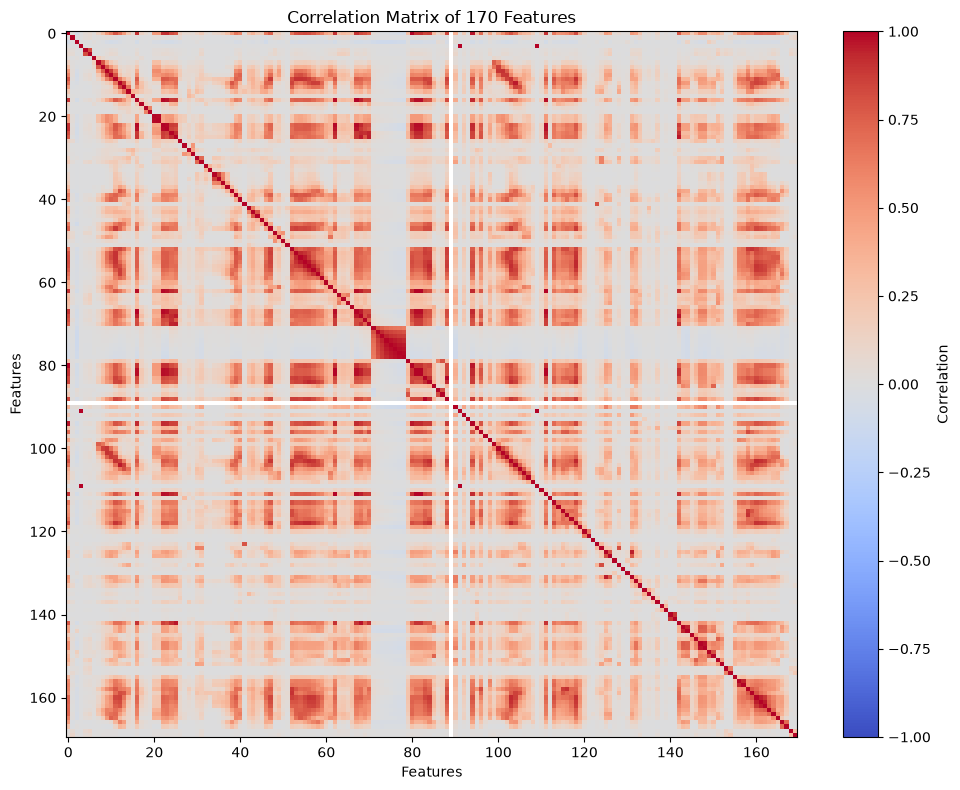

In [5]:
corr_matrix = X_train_imp.corr()
plt.figure(figsize=(10, 8))
plt.imshow(
    corr_matrix,
    aspect="auto",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.colorbar(label="Correlation")
plt.title("Correlation Matrix of 170 Features")
plt.xlabel("Features")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

#### 1(b)(iv) Features with Highest CV

I select the 13 features with the highest coefficient of variation for visualization. 
I standardize the attributes first, then draw scatter plots and box plots for these features.
From these plots, some features show differences between the two classes, but scatter plots alone are not enough to determine feature significance.

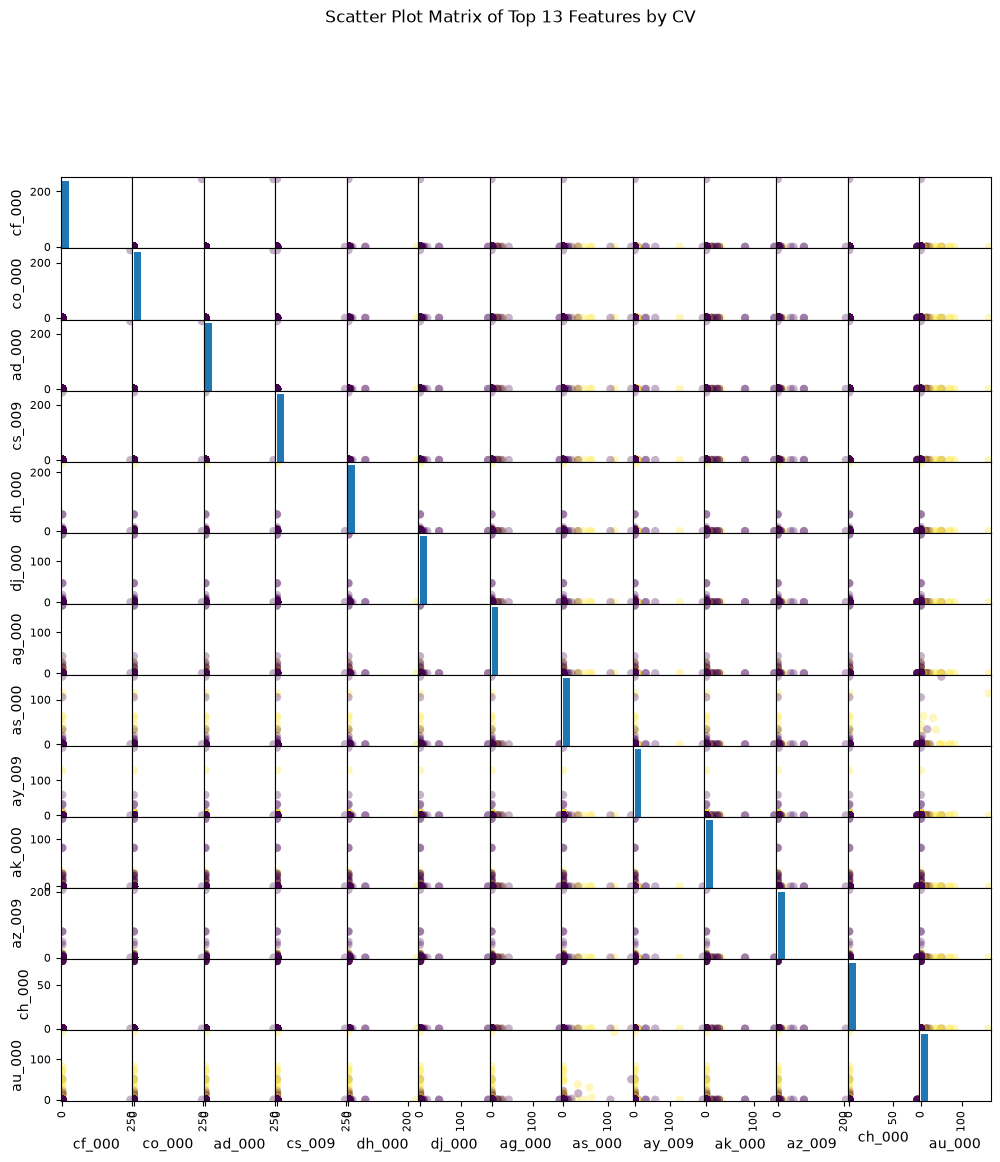

In [6]:
from sklearn.preprocessing import StandardScaler
from pandas.plotting import scatter_matrix
scaler = StandardScaler()
X_train_std = pd.DataFrame(
    scaler.fit_transform(X_train_imp),
    columns=X_train_imp.columns
)
top_13_features = cv_df.sort_values("CV", ascending=False).head(13).index.tolist()
color_map = y_train.map({"neg": 0, "pos": 1})
scatter_matrix(
    X_train_std[top_13_features],
    figsize=(12, 12),
    diagonal="hist",
    alpha=0.3,
    c=color_map,
    marker="o"
)
plt.suptitle("Scatter Plot Matrix of Top 13 Features by CV", y=1.02)
plt.show()

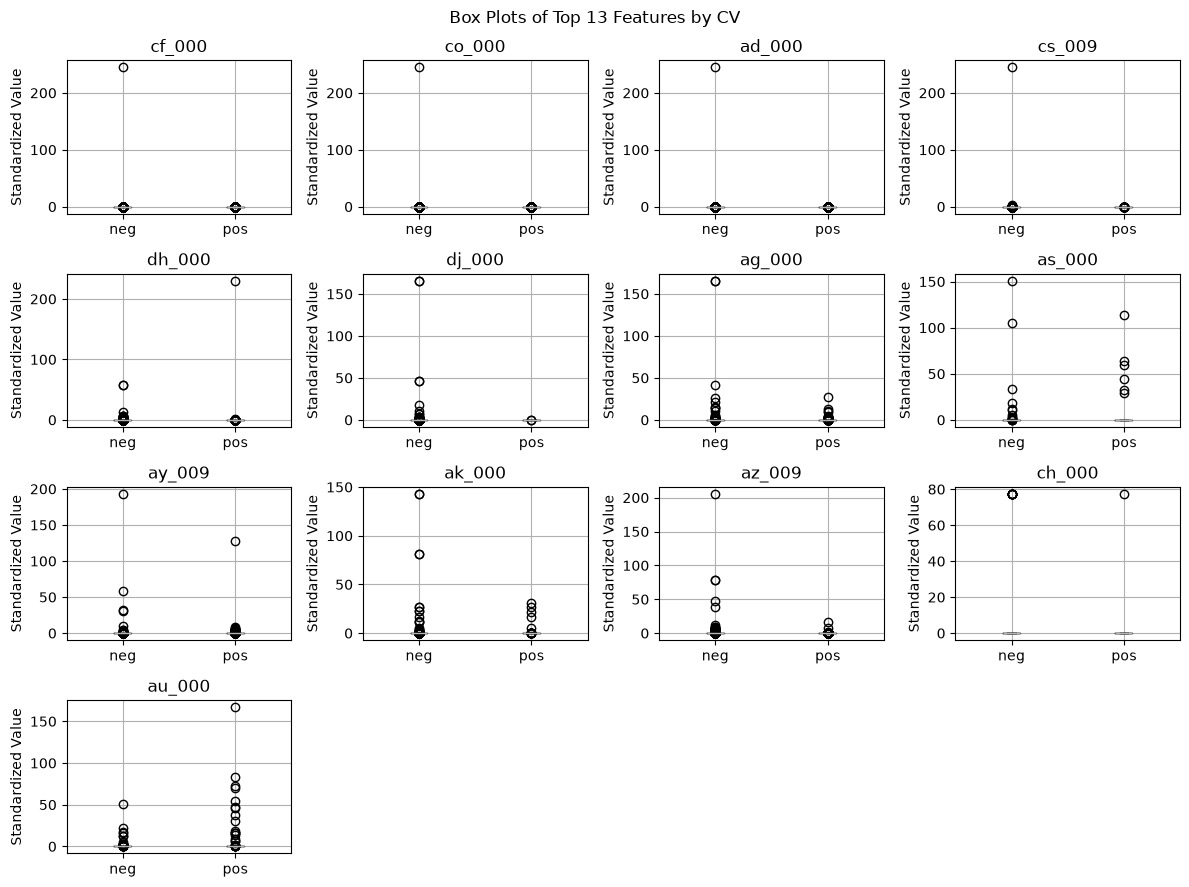

In [7]:
plot_df = X_train_std[top_13_features].copy()
plot_df["class"] = y_train.values
fig, axes = plt.subplots(4, 4, figsize=(12, 9))
axes = axes.flatten()
for i, feature in enumerate(top_13_features):
    plot_df.boxplot(column=feature, by="class", ax=axes[i])
    axes[i].set_title(feature)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Standardized Value")
for j in range(len(top_13_features), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Box Plots of Top 13 Features by CV")
plt.tight_layout()
plt.show()

The scatter plots and box plots suggest that some of the selected high-CV features show different distributions for the two classes. 
However, there is still substantial overlap between the positive and negative classes. 
So, based on scatter plots alone, it is hard to make strong conclusions about feature significance.

#### 1(b)(v) Class Distribution

In [8]:
train_counts = y_train.value_counts()
print("Training set:")
print(train_counts)
print("\nPositive percentage:",
      (train_counts["pos"] / len(y_train)) * 100)
print("Negative percentage:",
      (train_counts["neg"] / len(y_train)) * 100)

Training set:
class
neg    59000
pos     1000
Name: count, dtype: int64

Positive percentage: 1.6666666666666667
Negative percentage: 98.33333333333333


The dataset is highly imbalanced because only about 1.67% of the training samples are positive.

### 1(c) Random Forest without Class Imbalance Compensation

In [9]:
y_train_bin = y_train.map({"neg": 0, "pos": 1})
y_test_bin = y_test.map({"neg": 0, "pos": 1})
rf_model = RandomForestClassifier(
    n_estimators=500,
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_imp, y_train_bin)
train_pred = rf_model.predict(X_train_imp)
test_pred = rf_model.predict(X_test_imp)
train_prob = rf_model.predict_proba(X_train_imp)[:, 1]
test_prob = rf_model.predict_proba(X_test_imp)[:, 1]
train_cm = confusion_matrix(y_train_bin, train_pred)
test_cm = confusion_matrix(y_test_bin, test_pred)
train_accuracy = accuracy_score(y_train_bin, train_pred)
test_accuracy = accuracy_score(y_test_bin, test_pred)
train_error = 1 - train_accuracy
test_error = 1 - test_accuracy
train_auc = roc_auc_score(y_train_bin, train_prob)
test_auc = roc_auc_score(y_test_bin, test_prob)
oob_error = 1 - rf_model.oob_score_
print("Training Confusion Matrix:")
print(train_cm)
print("\nTest Confusion Matrix:")
print(test_cm)
print("\nTraining Error:", train_error)
print("Test Error:", test_error)
print("\nTraining AUC:", train_auc)
print("Test AUC:", test_auc)
print("\nOOB Error:", oob_error)

Training Confusion Matrix:
[[59000     0]
 [    0  1000]]

Test Confusion Matrix:
[[15606    19]
 [  103   272]]

Training Error: 0.0
Test Error: 0.007624999999999993

Training AUC: 1.0
Test AUC: 0.9943158613333334

OOB Error: 0.005800000000000027


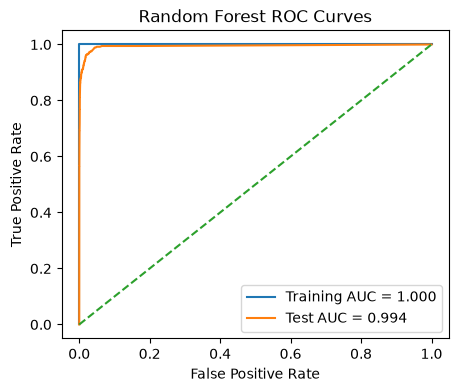

In [10]:
train_fpr, train_tpr, _ = roc_curve(
    y_train_bin,
    train_prob
)
test_fpr, test_tpr, _ = roc_curve(
    y_test_bin,
    test_prob
)
plt.figure(figsize=(5, 4))
plt.plot(
    train_fpr,
    train_tpr,
    label=f"Training AUC = {train_auc:.3f}"
)
plt.plot(
    test_fpr,
    test_tpr,
    label=f"Test AUC = {test_auc:.3f}"
)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

The OOB error is about 0.58%, which is close to the test error of about 0.76%. The model has a high test AUC of about 0.994.

## 1(d) Random Forest with Class Imbalance Compensation

Class imbalance can be handled using class weights, over-sampling, or under-sampling. I use balanced class weights for the random forest.

In [11]:
rf_balanced = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    oob_score=True,
    random_state=42,
    n_jobs=-1
)
rf_balanced.fit(
    X_train_imp,
    y_train_bin
)
balanced_train_pred = rf_balanced.predict(
    X_train_imp
)
balanced_test_pred = rf_balanced.predict(
    X_test_imp
)
balanced_train_prob = rf_balanced.predict_proba(
    X_train_imp
)[:, 1]
balanced_test_prob = rf_balanced.predict_proba(
    X_test_imp
)[:, 1]
balanced_train_cm = confusion_matrix(
    y_train_bin,
    balanced_train_pred
)
balanced_test_cm = confusion_matrix(
    y_test_bin,
    balanced_test_pred
)
balanced_train_error = 1 - accuracy_score(
    y_train_bin,
    balanced_train_pred
)
balanced_test_error = 1 - accuracy_score(
    y_test_bin,
    balanced_test_pred
)
balanced_train_auc = roc_auc_score(
    y_train_bin,
    balanced_train_prob
)
balanced_test_auc = roc_auc_score(
    y_test_bin,
    balanced_test_prob
)
balanced_oob_error = 1 - rf_balanced.oob_score_
print("Training Confusion Matrix:")
print(balanced_train_cm)
print("\nTest Confusion Matrix:")
print(balanced_test_cm)
print("\nTraining Error:", balanced_train_error)
print("Test Error:", balanced_test_error)
print("\nTraining AUC:", balanced_train_auc)
print("Test AUC:", balanced_test_auc)
print("\nOOB Error:", balanced_oob_error)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


Training Confusion Matrix:
[[58990    10]
 [    0  1000]]

Test Confusion Matrix:
[[15570    55]
 [   96   279]]

Training Error: 0.0001666666666666483
Test Error: 0.009437499999999988

Training AUC: 0.9999999999999999
Test AUC: 0.994400256

OOB Error: 0.020066666666666677


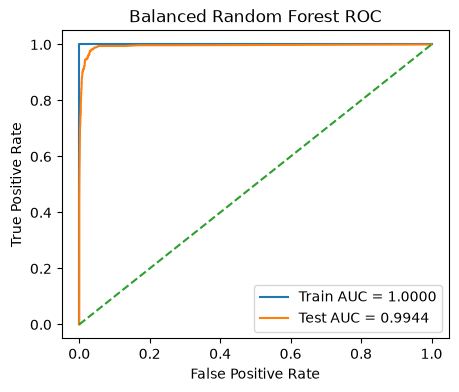

In [12]:
balanced_train_fpr, balanced_train_tpr, _ = roc_curve(
    y_train_bin,
    balanced_train_prob
)
balanced_test_fpr, balanced_test_tpr, _ = roc_curve(
    y_test_bin,
    balanced_test_prob
)
plt.figure(figsize=(5, 4))
plt.plot(
    balanced_train_fpr,
    balanced_train_tpr,
    label=f"Train AUC = {balanced_train_auc:.4f}"
)
plt.plot(
    balanced_test_fpr,
    balanced_test_tpr,
    label=f"Test AUC = {balanced_test_auc:.4f}"
)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Balanced Random Forest ROC")
plt.legend()
plt.show()

The balanced random forest slightly reduces false negatives, but it creates more false positives. Its test error is slightly higher than the original random forest, while the test AUC is almost the same.

### 1(e) XGBoost with L1 Regularization

I use 5-fold cross-validation to select the L1 regularization parameter alpha. The model is trained without compensating for class imbalance.

In [13]:
xgb_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    random_state=42,
    n_jobs=-1
)
param_grid = {
    "reg_alpha": [0, 0.01, 0.1, 1, 10, 100]
}
xgb_grid = GridSearchCV(
    xgb_model,
    param_grid,
    cv=xgb_cv,
    scoring="accuracy",
    n_jobs=-1
)
xgb_grid.fit(
    X_train_imp,
    y_train_bin
)
print("Best alpha:", xgb_grid.best_params_["reg_alpha"])
print("Best CV accuracy:", xgb_grid.best_score_)
print("CV error:", 1 - xgb_grid.best_score_)

Best alpha: 1
Best CV accuracy: 0.9929666666666668
CV error: 0.007033333333333225


In [14]:
best_xgb = xgb_grid.best_estimator_
best_xgb.fit(X_train_imp, y_train_bin)
xgb_train_pred = best_xgb.predict(X_train_imp)
xgb_test_pred = best_xgb.predict(X_test_imp)
xgb_train_prob = best_xgb.predict_proba(X_train_imp)[:, 1]
xgb_test_prob = best_xgb.predict_proba(X_test_imp)[:, 1]
xgb_train_cm = confusion_matrix(y_train_bin, xgb_train_pred)
xgb_test_cm = confusion_matrix(y_test_bin, xgb_test_pred)
xgb_train_error = 1 - accuracy_score(
    y_train_bin,
    xgb_train_pred
)
xgb_test_error = 1 - accuracy_score(
    y_test_bin,
    xgb_test_pred
)
xgb_train_auc = roc_auc_score(
    y_train_bin,
    xgb_train_prob
)
xgb_test_auc = roc_auc_score(
    y_test_bin,
    xgb_test_prob
)
print("Training Confusion Matrix:")
print(xgb_train_cm)
print("\nTest Confusion Matrix:")
print(xgb_test_cm)
print("\nCV Error:", 1 - xgb_grid.best_score_)
print("Training Error:", xgb_train_error)
print("Test Error:", xgb_test_error)
print("\nTraining AUC:", xgb_train_auc)
print("Test AUC:", xgb_test_auc)

Training Confusion Matrix:
[[58940    60]
 [  227   773]]

Test Confusion Matrix:
[[15603    22]
 [  117   258]]

CV Error: 0.007033333333333225
Training Error: 0.004783333333333362
Test Error: 0.00868749999999996

Training AUC: 0.995656779661017
Test AUC: 0.9955456


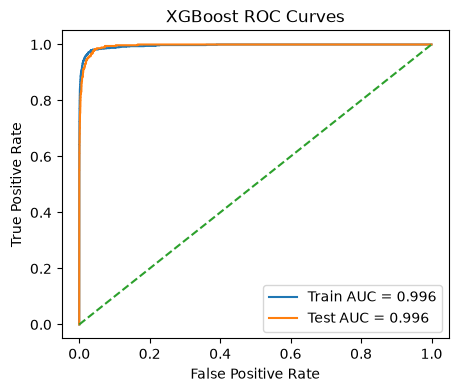

In [15]:
xgb_train_fpr, xgb_train_tpr, _ = roc_curve(
    y_train_bin,
    xgb_train_prob
)
xgb_test_fpr, xgb_test_tpr, _ = roc_curve(
    y_test_bin,
    xgb_test_prob
)
plt.figure(figsize=(5, 4))
plt.plot(
    xgb_train_fpr,
    xgb_train_tpr,
    label=f"Train AUC = {xgb_train_auc:.3f}"
)
plt.plot(
    xgb_test_fpr,
    xgb_test_tpr,
    label=f"Test AUC = {xgb_test_auc:.3f}"
)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

The 5-fold CV error is about 0.70%, which is close to the test error of about 0.87%. The XGBoost model also has a high test AUC of about 0.996, and performs slightly better than the random forest model.

### 1(f) XGBoost with SMOTE

I use SMOTE inside the cross-validation pipeline so that oversampling is performed only on the training portion of each fold.

In [16]:
smote_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        random_state=42,
        n_jobs=-1
    ))
])
smote_param_grid = {
    "xgb__reg_alpha": [0, 0.01, 0.1, 1, 10, 100]
}
smote_grid = GridSearchCV(
    smote_pipeline,
    smote_param_grid,
    cv=xgb_cv,
    scoring="accuracy",
    n_jobs=-1
)
smote_grid.fit(
    X_train_imp,
    y_train_bin
)
print(
    "Best alpha:",
    smote_grid.best_params_["xgb__reg_alpha"]
)
print(
    "Best CV accuracy:",
    smote_grid.best_score_
)
print(
    "CV error:",
    1 - smote_grid.best_score_
)

Best alpha: 0
Best CV accuracy: 0.9793833333333334
CV error: 0.020616666666666617


In [17]:
best_smote_model = smote_grid.best_estimator_
smote_train_pred = best_smote_model.predict(X_train_imp)
smote_test_pred = best_smote_model.predict(X_test_imp)
smote_train_prob = best_smote_model.predict_proba(X_train_imp)[:, 1]
smote_test_prob = best_smote_model.predict_proba(X_test_imp)[:, 1]
smote_train_cm = confusion_matrix(y_train_bin, smote_train_pred)
smote_test_cm = confusion_matrix(y_test_bin, smote_test_pred)
smote_train_error = 1 - accuracy_score(
    y_train_bin, smote_train_pred
)
smote_test_error = 1 - accuracy_score(
    y_test_bin, smote_test_pred
)
smote_train_auc = roc_auc_score(
    y_train_bin, smote_train_prob
)
smote_test_auc = roc_auc_score(
    y_test_bin, smote_test_prob
)
print("Training Confusion Matrix:")
print(smote_train_cm)
print("\nTest Confusion Matrix:")
print(smote_test_cm)
print("\nCV Error:", 1 - smote_grid.best_score_)
print("Training Error:", smote_train_error)
print("Test Error:", smote_test_error)
print("\nTraining AUC:", smote_train_auc)
print("Test AUC:", smote_test_auc)

Training Confusion Matrix:
[[57923  1077]
 [   72   928]]

Test Confusion Matrix:
[[15325   300]
 [   25   350]]

CV Error: 0.020616666666666617
Training Error: 0.01915
Test Error: 0.020312499999999956

Training AUC: 0.9937068813559322
Test AUC: 0.9929808213333333


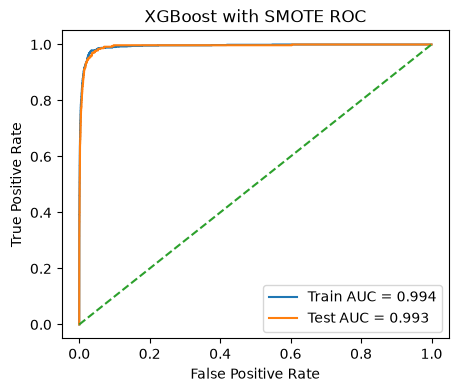

In [18]:
smote_train_fpr, smote_train_tpr, _ = roc_curve(
    y_train_bin, smote_train_prob
)
smote_test_fpr, smote_test_tpr, _ = roc_curve(
    y_test_bin, smote_test_prob
)
plt.figure(figsize=(5, 4))
plt.plot(
    smote_train_fpr,
    smote_train_tpr,
    label=f"Train AUC = {smote_train_auc:.3f}"
)
plt.plot(
    smote_test_fpr,
    smote_test_tpr,
    label=f"Test AUC = {smote_test_auc:.3f}"
)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost with SMOTE ROC")
plt.legend()
plt.show()

Compared with the model without SMOTE, the SMOTE model has a slightly higher test error and slightly lower AUC. However, it identifies many more positive cases. The number of correctly classified positive test cases increases from 258 to 350, although the number of false positives also increases. Therefore, SMOTE improves minority-class detection but reduces overall accuracy slightly.

## 2. ISLR 6.6.3

**(a)** iv. **Steadily decrease.**  
As \(s\) increases, the constraint becomes less strict, so the model can fit the training data better and training RSS decreases.

**(b)** ii. **Decrease initially, then eventually increase.**  
A larger \(s\) makes the model more flexible. At first this can reduce test error, but too much flexibility may cause overfitting.

**(c)** iii. **Steadily increase.**  
As \(s\) increases, the model becomes more flexible, so the variance increases.

**(d)** iv. **Steadily decrease.**  
More flexibility reduces the bias of the model.

**(e)** v. **Remain constant.**  
The irreducible error is caused by noise in the data and does not depend on \(s\).

## 3. ISLR 6.6.5

Let $x=x_{11}=x_{12}$. Since $x_{11}+x_{21}=0$, we also have $x_{21}=x_{22}=-x$, and $y_2=-y_1$.

**(a)** The ridge regression problem is

$$
\min_{\beta_1,\beta_2}
2[y_1-x(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2).
$$

**(b)** The objective is symmetric in $\beta_1$ and $\beta_2$. The ridge penalty is minimized when the two coefficients are equal for a fixed value of their sum. Therefore,

$$
\hat{\beta}_1=\hat{\beta}_2.
$$

**(c)** The lasso problem is

$$
\min_{\beta_1,\beta_2}
2[y_1-x(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|).
$$

**(d)** Unlike ridge, the lasso solution does not have to be unique. The fitted values depend only on $\beta_1+\beta_2$. If the optimal sum is $s$, then any coefficients with the same sign satisfying

$$
\beta_1+\beta_2=s
$$

have the same lasso penalty $|s|$. Therefore, there can be many equivalent lasso solutions.

## 4. ISLR 8.4.5

Using majority vote, 6 out of the 10 trees have $P(\text{Red}|X)>0.5$, so the final classification is **Red**.

Using the average probability,

$$
\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
=0.45.
$$

Since $0.45<0.5$, the classification using the average probability is **Green**.

Therefore:

- Majority vote: **Red**
- Average probability: **Green**

## 5. ISLR 9.7.3

The optimal separating hyperplane is

$$
-2X_1+2X_2+1=0,
$$

or equivalently,

$$
X_2=X_1-0.5.
$$

The two margin lines are

$$
X_2=X_1
$$

and

$$
X_2=X_1-1.
$$

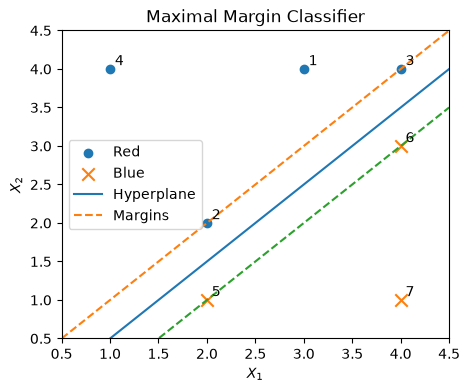

In [19]:
red = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4]
])
blue = np.array([
    [2, 1],
    [4, 3],
    [4, 1]
])
plt.figure(figsize=(5, 4))
plt.scatter(red[:, 0], red[:, 1],
            marker="o", label="Red")
plt.scatter(blue[:, 0], blue[:, 1],
            marker="x", s=80, label="Blue")
x = np.linspace(0.5, 4.5, 100)
plt.plot(x, x - 0.5, label="Hyperplane")
plt.plot(x, x, "--", label="Margins")
plt.plot(x, x - 1, "--")
for i, (x1, x2) in enumerate(np.vstack((red, blue)), start=1):
    plt.text(x1 + 0.05, x2 + 0.05, str(i))
plt.xlim(0.5, 4.5)
plt.ylim(0.5, 4.5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.legend()
plt.title("Maximal Margin Classifier")
plt.show()

**(c)** Classify an observation as **Red** if

$$
1-2X_1+2X_2>0,
$$

and classify it as **Blue** otherwise. Thus,

$$
\beta_0=1,\qquad \beta_1=-2,\qquad \beta_2=2.
$$

**(e)** The support vectors are observations **2, 3, 5, and 6**.

**(f)** Observation 7 is not a support vector and is away from the margin. Therefore, a small movement of observation 7 will not change the maximal margin hyperplane.

**(a), (b), (d)** The plot shows the observations, the optimal separating hyperplane, and the two margins.

**(g)** One separating hyperplane that is not optimal is

$$
X_2 = X_1 - 0.25.
$$

It still separates the original two classes, but its margin is smaller.

**(h)** If we add a Blue observation at $(2,3)$, the classes are no longer linearly separable because this point lies inside the region of the Red observations.

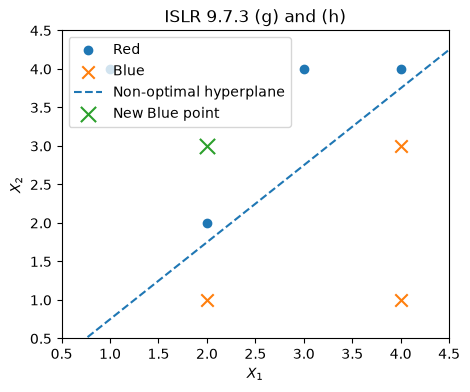

In [20]:
plt.figure(figsize=(5, 4))
plt.scatter(
    red[:, 0],
    red[:, 1],
    marker="o",
    label="Red"
)
plt.scatter(
    blue[:, 0],
    blue[:, 1],
    marker="x",
    s=80,
    label="Blue"
)
x = np.linspace(0.5, 4.5, 100)
plt.plot(
    x,
    x - 0.25,
    "--",
    label="Non-optimal hyperplane"
)
plt.scatter(
    2,
    3,
    marker="x",
    s=120,
    label="New Blue point"
)
plt.xlim(0.5, 4.5)
plt.ylim(0.5, 4.5)
plt.xlabel("$X_1$")
plt.ylabel("$X_2$")
plt.title("ISLR 9.7.3 (g) and (h)")
plt.legend()
plt.show()